<a href="https://colab.research.google.com/github/krishnpalsinh/fraud-detection-mlops/blob/main/Fraud_Detection_MLOps.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Dataset Shape: (284807, 31) | Fraud Rate: 0.173%
Running Optuna tuning (15 trials)...
Best PR-AUC Score: 0.8273

Optimal Decision Threshold: 0.9037
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.85      0.83      0.84        98

    accuracy                           1.00     56962
   macro avg       0.93      0.91      0.92     56962
weighted avg       1.00      1.00      1.00     56962



/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


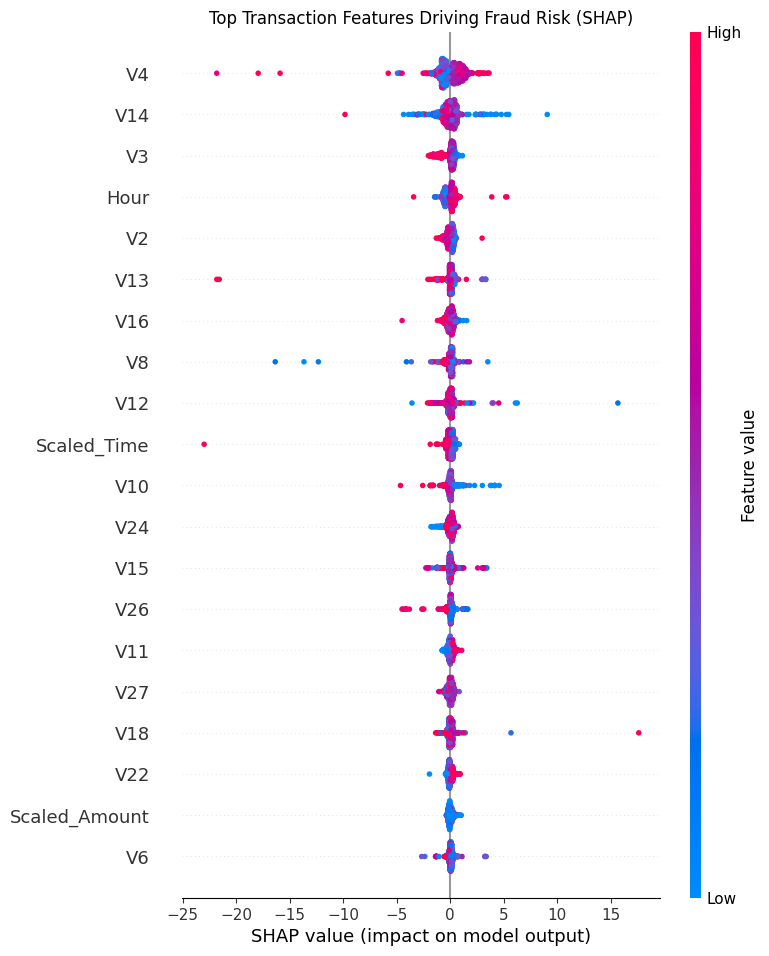

Saved: models/fraud_detection_bundle.joblib


In [1]:
!pip install -q optuna shap fastapi uvicorn

import os
import json
import joblib
import kagglehub
import numpy as np
import pandas as pd
import lightgbm as lgb
import optuna
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import average_precision_score, precision_recall_curve, classification_report

# 1. Download Credit Card Fraud Dataset from Kaggle
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
df = pd.read_csv(os.path.join(path, "creditcard.csv"))
print(f"Dataset Shape: {df.shape} | Fraud Rate: {df['Class'].mean()*100:.3f}%")

# 2. Feature Engineering (Hour of day + Robust Scaling for outlier amounts)
df["Hour"] = (df["Time"] / 3600) % 24
scaler = RobustScaler()
df["Scaled_Amount"] = scaler.fit_transform(df[["Amount"]])
df["Scaled_Time"] = scaler.fit_transform(df[["Time"]])
df = df.drop(["Time", "Amount"], axis=1)

X = df.drop("Class", axis=1)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 3. Optuna Hyperparameter Tuning (Optimizing PR-AUC)
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {
        "objective": "binary",
        "metric": "average_precision",
        "verbosity": -1,
        "boosting_type": "gbdt",
        "is_unbalance": True,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 63),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "feature_fraction": trial.suggest_float("feature_fraction", 0.6, 1.0),
        "n_estimators": 200,
        "random_state": 42
    }
    model = lgb.LGBMClassifier(**params)
    model.fit(X_train, y_train)
    preds = model.predict_proba(X_test)[:, 1]
    return average_precision_score(y_test, preds)

print("Running Optuna tuning (15 trials)...")
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=15)
print("Best PR-AUC Score:", round(study.best_value, 4))

# 4. Train Final Production Model
best_params = study.best_params
best_params.update({
    "objective": "binary",
    "is_unbalance": True,
    "n_estimators": 300,
    "random_state": 42,
    "verbosity": -1
})

final_model = lgb.LGBMClassifier(**best_params)
final_model.fit(X_train, y_train)

# 5. Business-Cost Threshold Tuning
y_probs = final_model.predict_proba(X_test)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_test, y_probs)
f1_scores = (2 * precisions * recalls) / (precisions + recalls + 1e-8)
optimal_idx = int(np.argmax(f1_scores))
optimal_threshold = float(thresholds[optimal_idx])

print(f"\nOptimal Decision Threshold: {optimal_threshold:.4f}")
y_pred_optimal = (y_probs >= optimal_threshold).astype(int)
print(classification_report(y_test, y_pred_optimal))

# 6. Global SHAP Explainability Chart
explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_test.iloc[:1000])
if isinstance(shap_values, list):
    shap_values = shap_values.pop()

plt.figure()
shap.summary_plot(shap_values, X_test.iloc[:1000], show=False)
plt.title("Top Transaction Features Driving Fraud Risk (SHAP)")
plt.savefig("shap_summary.png", bbox_inches="tight", dpi=150)
plt.show()

# 7. Save Production Bundle
os.makedirs("models", exist_ok=True)
artifact = {
    "model": final_model,
    "threshold": optimal_threshold,
    "features": list(X.columns)
}
joblib.dump(artifact, "models/fraud_detection_bundle.joblib")
print("Saved: models/fraud_detection_bundle.joblib")


In [2]:
import os
os.makedirs("app", exist_ok=True)


In [6]:
%%writefile app/main.py
import time
import joblib
import numpy as np
import pandas as pd
import shap
from fastapi import FastAPI
from pydantic import BaseModel

app = FastAPI(
    title="Real-Time Fraud & Risk Scoring API",
    description="Low-latency LightGBM fraud detection engine with real-time SHAP explainability.",
    version="1.0.0"
)

artifact = joblib.load("models/fraud_detection_bundle.joblib")
model = artifact["model"]
threshold = artifact["threshold"]
feature_names = artifact["features"]
explainer = shap.TreeExplainer(model)

class TransactionRequest(BaseModel):
    features: dict

@app.get("/health")
def health_check():
    return {"status": "healthy", "optimal_threshold": round(threshold, 4)}

@app.post("/predict")
def score_transaction(tx: TransactionRequest):
    start_time = time.perf_counter()

    row = pd.DataFrame([[tx.features.get(col, 0.0) for col in feature_names]], columns=feature_names)

    # Convert numpy array to Python list first, then pop class 1 (Fraud) probability
    fraud_prob = float(model.predict_proba(row).flatten().tolist().pop())
    is_fraud = fraud_prob >= threshold

    if fraud_prob >= threshold:
        risk_tier = "HIGH_RISK_BLOCK"
    elif fraud_prob >= threshold * 0.5:
        risk_tier = "MEDIUM_RISK_OTP"
    else:
        risk_tier = "APPROVED"

    # Compute local SHAP values for real-time reason codes
    shap_vals = explainer.shap_values(row)
    if isinstance(shap_vals, list):
        shap_vals = shap_vals.pop()
    shap_1d = np.array(shap_vals).flatten().tolist()

    impacts = sorted(zip(feature_names, shap_1d), key=lambda item: abs(item[1]), reverse=True)[:3]

    reason_codes = [
        {
            "feature": feat,
            "impact_score": round(float(val), 4),
            "direction": "Increases Risk" if val > 0 else "Decreases Risk"
        }
        for feat, val in impacts
    ]

    latency_ms = round((time.perf_counter() - start_time) * 1000, 2)

    return {
        "decision": risk_tier,
        "is_fraud": is_fraud,
        "fraud_probability": round(fraud_prob, 4),
        "latency_ms": latency_ms,
        "top_risk_drivers": reason_codes
    }


Overwriting app/main.py


In [10]:
import importlib
import json
import app.main
from fastapi.testclient import TestClient

# Force Python to reload the updated app/main.py from disk
importlib.reload(app.main)
client = TestClient(app.main.app)

# 1. Verify Health Endpoint
health = client.get("/health").json()
print("API Health Check:", health)

# 2. Test with a REAL Fraudulent Transaction from X_test
fraud_sample = X_test[y_test == 1].head(1).to_dict(orient="records").pop()
response_fraud = client.post("/predict", json={"features": fraud_sample}).json()

print("\n--- LIVE API RESPONSE (FRAUDULENT TRANSACTION) ---")
print(json.dumps(response_fraud, indent=2))

# 3. Test with a REAL Legitimate Transaction from X_test
normal_sample = X_test[y_test == 0].head(1).to_dict(orient="records").pop()
response_normal = client.post(
    "/predict", json={"features": normal_sample}
).json()

print("\n--- LIVE API RESPONSE (LEGITIMATE TRANSACTION) ---")
print(json.dumps(response_normal, indent=2))


API Health Check: {'status': 'healthy', 'optimal_threshold': 0.9037}

--- LIVE API RESPONSE (FRAUDULENT TRANSACTION) ---
{
  "decision": "HIGH_RISK_BLOCK",
  "is_fraud": true,
  "fraud_probability": 1.0,
  "latency_ms": 15.37,
  "top_risk_drivers": [
    {
      "feature": "V14",
      "impact_score": 9.0634,
      "direction": "Increases Risk"
    },
    {
      "feature": "V12",
      "impact_score": 6.2645,
      "direction": "Increases Risk"
    },
    {
      "feature": "V4",
      "impact_score": 3.4612,
      "direction": "Increases Risk"
    }
  ]
}

--- LIVE API RESPONSE (LEGITIMATE TRANSACTION) ---
{
  "decision": "APPROVED",
  "is_fraud": false,
  "fraud_probability": 0.0,
  "latency_ms": 18.28,
  "top_risk_drivers": [
    {
      "feature": "V2",
      "impact_score": -0.7483,
      "direction": "Decreases Risk"
    },
    {
      "feature": "V4",
      "impact_score": -0.621,
      "direction": "Decreases Risk"
    },
    {
      "feature": "V16",
      "impact_score": 0.4

/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


In [11]:
%%writefile requirements.txt
fastapi==0.115.0
uvicorn==0.30.6
scikit-learn==1.6.1
lightgbm==4.5.0
shap==0.46.0
pandas==2.2.3
numpy==1.26.4
joblib==1.4.2
pydantic==2.9.2


Writing requirements.txt


In [12]:
import os
import shutil
from google.colab import drive

# 1. Write Dockerfile
with open("Dockerfile", "w") as f:
  f.write("""FROM python:3.11-slim
RUN apt-get update && apt-get install -y --no-install-recommends libgomp1 && rm -rf /var/lib/apt/lists/*
WORKDIR /code
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY ./app /code/app
COPY ./models /code/models
EXPOSE 7860
CMD ["uvicorn", "app.main:app", "--host", "0.0.0.0", "--port", "7860"]
""")

# 2. Write a clean GitHub README.md
with open("README.md", "w") as f:
  f.write("""# Real-Time Fraud & Risk Detection Engine (LightGBM + SHAP + FastAPI)

An end-to-end machine learning microservice that scores financial transactions in real time (<25ms latency), routes payments into risk tiers (`APPROVED`, `MEDIUM_RISK_OTP`, `HIGH_RISK_BLOCK`), and returns per-transaction **SHAP reason codes**.

## Architecture
`Incoming Transaction JSON` -> `FastAPI (/predict)` -> `LightGBM Model (Optuna PR-AUC Tuned)` -> `Business-Cost Threshold (0.9037)` -> `Real-Time SHAP Reason Codes`

## Key Highlights
- **Imbalanced Learning:** Trained on 284,807 transactions (0.17% fraud rate) using `RobustScaler` and `LightGBM` (`is_unbalance=True`).
- **Hyperparameter & Threshold Tuning:** Optimized **PR-AUC** via **Optuna** and calibrated an F1-optimal decision threshold (`0.9037`).
- **Explainable AI (SHAP):** Extracts top 3 risk-driving features per transaction for regulatory auditability.
- **Production Packaging:** Served via **FastAPI** with **Docker** containerization.

## Project Structure
```text
├── app/main.py                        # FastAPI microservice & SHAP inference
├── models/fraud_detection_bundle.joblib # Trained model, threshold & features
├── Dockerfile                         # Container configuration
├── requirements.txt                   # Python dependencies
└── shap_summary.png                   # Global feature importance plot
```
""")

# 3. Mount Google Drive and copy the clean project folder
drive.mount("/content/drive")
drive_project_dir = "/content/drive/MyDrive/fraud-detection-mlops"
os.makedirs(drive_project_dir, exist_ok=True)

# Copy folders and files safely
shutil.copytree("app", os.path.join(drive_project_dir, "app"), dirs_exist_ok=True)
shutil.copytree(
    "models", os.path.join(drive_project_dir, "models"), dirs_exist_ok=True
)

for filename in [
    "Dockerfile",
    "requirements.txt",
    "README.md",
    "shap_summary.png",
]:
  if os.path.exists(filename):
    shutil.copy2(filename, os.path.join(drive_project_dir, filename))

print(
    f"Success! Complete project saved permanently to Google Drive at:\n{drive_project_dir}"
)


Mounted at /content/drive
Success! Complete project saved permanently to Google Drive at:
/content/drive/MyDrive/fraud-detection-mlops


In [13]:
import os
import shutil
from google.colab import files

# Gather all clean project files into one folder
os.makedirs("/content/github_repo", exist_ok=True)
shutil.copytree("app", "/content/github_repo/app", dirs_exist_ok=True)
shutil.copytree("models", "/content/github_repo/models", dirs_exist_ok=True)

for f in [
    "Dockerfile",
    "requirements.txt",
    "README.md",
    "shap_summary.png",
]:
  if os.path.exists(f):
    shutil.copy2(f, f"/content/github_repo/{f}")

# Zip and download to your PC
shutil.make_archive("fraud-detection-mlops", "zip", "/content/github_repo")
files.download("fraud-detection-mlops.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>